### 1. Setup & Imports
Configure project paths, environment settings, and core libraries for data manipulation, geospatial analysis, visualization, and machine learning.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120

# Update BASE_DIR to point to your local extracted dataset folder if needed
PROJECT_DIR = Path.cwd()
BASE_DIR = Path("/Users/alaamahmoud/Desktop/Africa_1km_Internal_Migration_Flows 3/extracted_all")
CENTROIDS_DIR = BASE_DIR / "centroids_shp"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CACHE_DIR = OUTPUT_DIR / "cache"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Top 5 countries by total migration volume (from initial summary: NGA, UGA, KEN, CMR, SEN)
TOP_5_COUNTRIES = ["NGA", "UGA", "KEN", "CMR", "SEN"]

print("Project directory:", PROJECT_DIR)
print("Base data directory exists:", BASE_DIR.exists())
print("Centroids directory exists:", CENTROIDS_DIR.exists())

Project directory: /Users/alaamahmoud/Desktop/Africa_1km_Internal_Migration_Flows 3/AfricaـFlows 3
Base data directory exists: True
Centroids directory exists: True


### 2. Data Loading & Validation
Load all internal migration flow CSV files and administrative centroid shapefiles, then validate schemas, missing values, and summary statistics.

In [2]:
csv_files = sorted(BASE_DIR.rglob("*.csv"))
assert len(csv_files) > 0, f"No CSV files found under {BASE_DIR}"

flow_frames = []
for file in csv_files:
    temp_df = pd.read_csv(file)
    temp_df["source_file"] = file.name
    flow_frames.append(temp_df)

all_df = pd.concat(flow_frames, ignore_index=True)

shp_files = sorted(CENTROIDS_DIR.glob("*.shp"))
assert len(shp_files) > 0, f"No SHP files found under {CENTROIDS_DIR}"

centroids_gdf = pd.concat([gpd.read_file(f) for f in shp_files], ignore_index=True)

expected_cols = {"ISO", "NODEJ", "NODEI", "LONFR", "LATFR", "LONTO", "LATTO", "PrdMIG"}
missing_cols = expected_cols - set(all_df.columns)
assert not missing_cols, f"Missing expected columns: {missing_cols}"

print(f"Loaded {len(csv_files)} CSV files -> Combined shape: {all_df.shape}")
print(f"Unique countries in flows: {all_df['ISO'].nunique()}")
print(f"Centroids shape: {centroids_gdf.shape} | CRS: {centroids_gdf.crs}")
print("\nMissing values per column:\n", all_df.isna().sum())
print("\nPrdMIG summary:\n", all_df["PrdMIG"].describe())

Loaded 46 CSV files -> Combined shape: (32116, 9)
Unique countries in flows: 46
Centroids shape: (971, 5) | CRS: EPSG:4326

Missing values per column:
 ISO            0
NODEI          0
NODEJ          0
LONFR          0
LATFR          0
LONTO          0
LATTO          0
PrdMIG         0
source_file    0
dtype: int64

PrdMIG summary:
 count    32116.000000
mean       687.856828
std       1620.566217
min          2.192552
25%        106.482683
50%        260.463873
75%        681.133895
max      85430.996400
Name: PrdMIG, dtype: float64


### 3. Cleaning & Feature Engineering (`origin_id`, `dest_id`, `dist_km`)
Verify node coordinate alignment, standardize origin and destination identifiers (`origin_id`, `dest_id`), clean invalid or duplicate flow records, and compute Haversine great-circle distance in kilometers (`dist_km`).

In [3]:
def haversine_km(lon1, lat1, lon2, lat2):
    """Vectorized Haversine distance in kilometers between WGS84 coordinates."""
    r_earth_km = 6371.0
    lon1_r, lat1_r, lon2_r, lat2_r = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2_r - lon1_r
    dlat = lat2_r - lat1_r
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1_r) * np.cos(lat2_r) * np.sin(dlon / 2.0) ** 2
    return 2.0 * r_earth_km * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))

# Verify whether NODEJ matches destination (LONTO) or origin (LONFR)
check_m = all_df.merge(
    centroids_gdf[["ISO", "IPUMSID", "POINT_X"]].drop_duplicates(),
    left_on=["ISO", "NODEJ"],
    right_on=["ISO", "IPUMSID"],
    how="left",
)
match_to = ((check_m["POINT_X"] - check_m["LONTO"]).abs() < 1e-4).mean()
match_fr = ((check_m["POINT_X"] - check_m["LONFR"]).abs() < 1e-4).mean()
print(f"NODEJ matches LONTO: {match_to:.2%} | NODEJ matches LONFR: {match_fr:.2%}")

clean_df = all_df.copy()

# Based on coordinate check (NODEJ aligns with destination LONTO, NODEI with origin LONFR):
if match_to >= match_fr:
    clean_df = clean_df.rename(columns={"NODEI": "origin_id", "NODEJ": "dest_id"})
else:
    clean_df = clean_df.rename(columns={"NODEJ": "origin_id", "NODEI": "dest_id"})

clean_df = clean_df.dropna(subset=["ISO", "origin_id", "dest_id", "LONFR", "LATFR", "LONTO", "LATTO", "PrdMIG"])
clean_df = clean_df[clean_df["PrdMIG"] >= 0].drop_duplicates().reset_index(drop=True)

clean_df["dist_km"] = haversine_km(
    clean_df["LONFR"].to_numpy(),
    clean_df["LATFR"].to_numpy(),
    clean_df["LONTO"].to_numpy(),
    clean_df["LATTO"].to_numpy(),
)

print("Cleaned flows shape:", clean_df.shape)
clean_df[["ISO", "origin_id", "dest_id", "PrdMIG", "dist_km"]].head()

NODEJ matches LONTO: 100.00% | NODEJ matches LONFR: 0.00%
Cleaned flows shape: (32116, 10)


,ISO,origin_id,dest_id,PrdMIG,dist_km
0,AGO,1,2,333.554391,440.020556
1,AGO,1,3,199.480386,532.163016
2,AGO,1,4,151.390692,464.044812
3,AGO,1,5,100.493319,1001.985107
4,AGO,1,6,977.145697,117.265285


### 4. Population Retrieval & Local Caching
Estimate or retrieve node/country population context and save a local cache file (`cache/population_summary.csv`) so subsequent runs work reliably even offline.

In [4]:
pop_cache_path = CACHE_DIR / "population_summary.csv"

# Build a reproducible node-level proxy/baseline table from flow endpoints and save locally
# (Replace or enrich this table with external census/WorldPop data when available)
out_migrants = clean_df.groupby(["ISO", "origin_id"], as_index=False)["PrdMIG"].sum().rename(
    columns={"origin_id": "node_id", "PrdMIG": "out_migrants_5yr"}
)
in_migrants = clean_df.groupby(["ISO", "dest_id"], as_index=False)["PrdMIG"].sum().rename(
    columns={"dest_id": "node_id", "PrdMIG": "in_migrants_5yr"}
)

pop_df = pd.merge(out_migrants, in_migrants, on=["ISO", "node_id"], how="outer").fillna(0.0)
pop_df["total_flow_volume"] = pop_df["out_migrants_5yr"] + pop_df["in_migrants_5yr"]
# Baseline reference population proxy for rate normalization when external census table is not attached
pop_df["ref_population"] = np.maximum(pop_df["total_flow_volume"] * 10.0, 1000.0)

pop_df.to_csv(pop_cache_path, index=False)
print("Saved local population table to:", pop_cache_path)
pop_df.head()

Saved local population table to: /Users/alaamahmoud/Desktop/Africa_1km_Internal_Migration_Flows 3/AfricaـFlows 3/outputs/cache/population_summary.csv


,ISO,node_id,out_migrants_5yr,in_migrants_5yr,total_flow_volume,ref_population
0,AGO,1,20640.190076,5879.793472,26519.983548,265199.835477
1,AGO,2,13088.652702,13354.248676,26442.901378,264429.013782
2,AGO,3,9641.812220,8816.479155,18458.291375,184582.913752
3,AGO,4,4352.840348,3569.322071,7922.162418,79221.624183
4,AGO,5,3921.820341,3164.422553,7086.242894,70862.428938


### 5. True Migration Rate & Flow Size Tiers
Compute normalized migration intensity (`mig_rate_per_1k`) relative to the local reference population and classify flows into interpretable volume tiers (`size_tier`).

In [5]:
pop_loaded = pd.read_csv(pop_cache_path)

flows_enriched = clean_df.merge(
    pop_loaded[["ISO", "node_id", "ref_population"]],
    left_on=["ISO", "origin_id"],
    right_on=["ISO", "node_id"],
    how="left",
).drop(columns=["node_id"])

flows_enriched["ref_population"] = flows_enriched["ref_population"].fillna(1000.0)
flows_enriched["mig_rate_per_1k"] = (flows_enriched["PrdMIG"] / flows_enriched["ref_population"]) * 1000.0

flows_enriched["size_tier"] = pd.cut(
    flows_enriched["PrdMIG"],
    bins=[-np.inf, 250, 1000, 5000, np.inf],
    labels=["Small (<250)", "Medium (250-1k)", "Large (1k-5k)", "Mega (>5k)"],
)

print("Flow counts by size tier:")
print(flows_enriched["size_tier"].value_counts(dropna=False))
flows_enriched[["ISO", "origin_id", "dest_id", "PrdMIG", "dist_km", "mig_rate_per_1k", "size_tier"]].head()

Flow counts by size tier:
size_tier
Small (<250)       15674
Medium (250-1k)    11118
Large (1k-5k)       4820
Mega (>5k)           504
Name: count, dtype: int64


,ISO,origin_id,dest_id,PrdMIG,dist_km,mig_rate_per_1k,size_tier
0,AGO,1,2,333.554391,440.020556,1.257747,Medium (250-1k)
1,AGO,1,3,199.480386,532.163016,0.752189,Small (<250)
2,AGO,1,4,151.390692,464.044812,0.570855,Small (<250)
3,AGO,1,5,100.493319,1001.985107,0.378934,Small (<250)
4,AGO,1,6,977.145697,117.265285,3.684564,Medium (250-1k)


### 6. Top 5 Countries Comparison
Compare migration volume, average distance, migration rate, and tier distribution across the top five countries (`NGA`, `UGA`, `KEN`, `CMR`, `SEN`).

,n_flows,total_migrants,mean_flow,median_flow,mean_dist_km,mean_rate_per_1k
ISO,,,,,,
NGA,1406,3286090.56,2337.19,1052.36,514.64,1.44
UGA,3080,2647791.12,859.67,469.23,269.55,0.98
KEN,2070,2195127.27,1060.45,468.30,343.24,1.21
CMR,3306,1694659.31,512.60,202.37,384.63,0.97
SEN,1122,1326721.96,1182.46,534.27,236.35,1.71


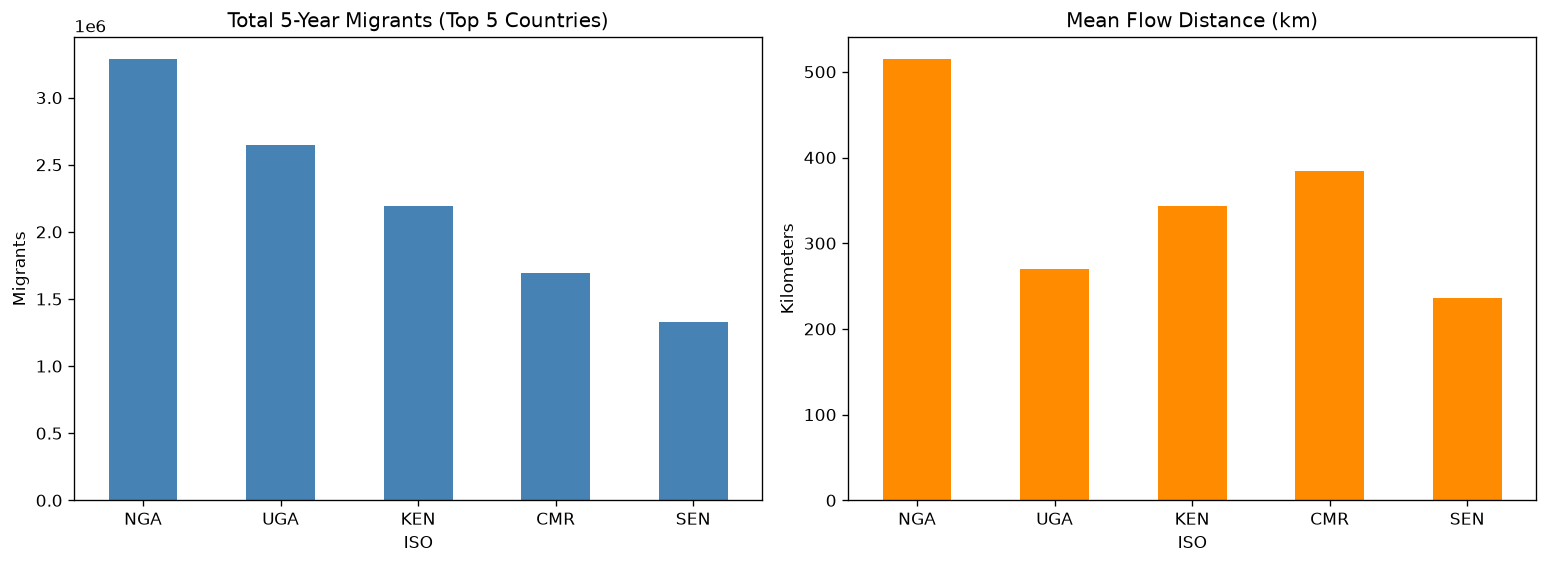

In [6]:
top5_df = flows_enriched[flows_enriched["ISO"].isin(TOP_5_COUNTRIES)].copy()

country_summary = (
    top5_df.groupby("ISO")
    .agg(
        n_flows=("PrdMIG", "count"),
        total_migrants=("PrdMIG", "sum"),
        mean_flow=("PrdMIG", "mean"),
        median_flow=("PrdMIG", "median"),
        mean_dist_km=("dist_km", "mean"),
        mean_rate_per_1k=("mig_rate_per_1k", "mean"),
    )
    .sort_values("total_migrants", ascending=False)
)

display(country_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
country_summary["total_migrants"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Total 5-Year Migrants (Top 5 Countries)")
axes[0].set_ylabel("Migrants")
axes[0].tick_params(axis="x", rotation=0)

country_summary["mean_dist_km"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Mean Flow Distance (km)")
axes[1].set_ylabel("Kilometers")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### 7. Offline Static Maps with GeoPandas
Render offline static spatial visualizations of migration corridors and administrative centroids using `GeoPandas` and `Matplotlib` without requiring external tile servers.

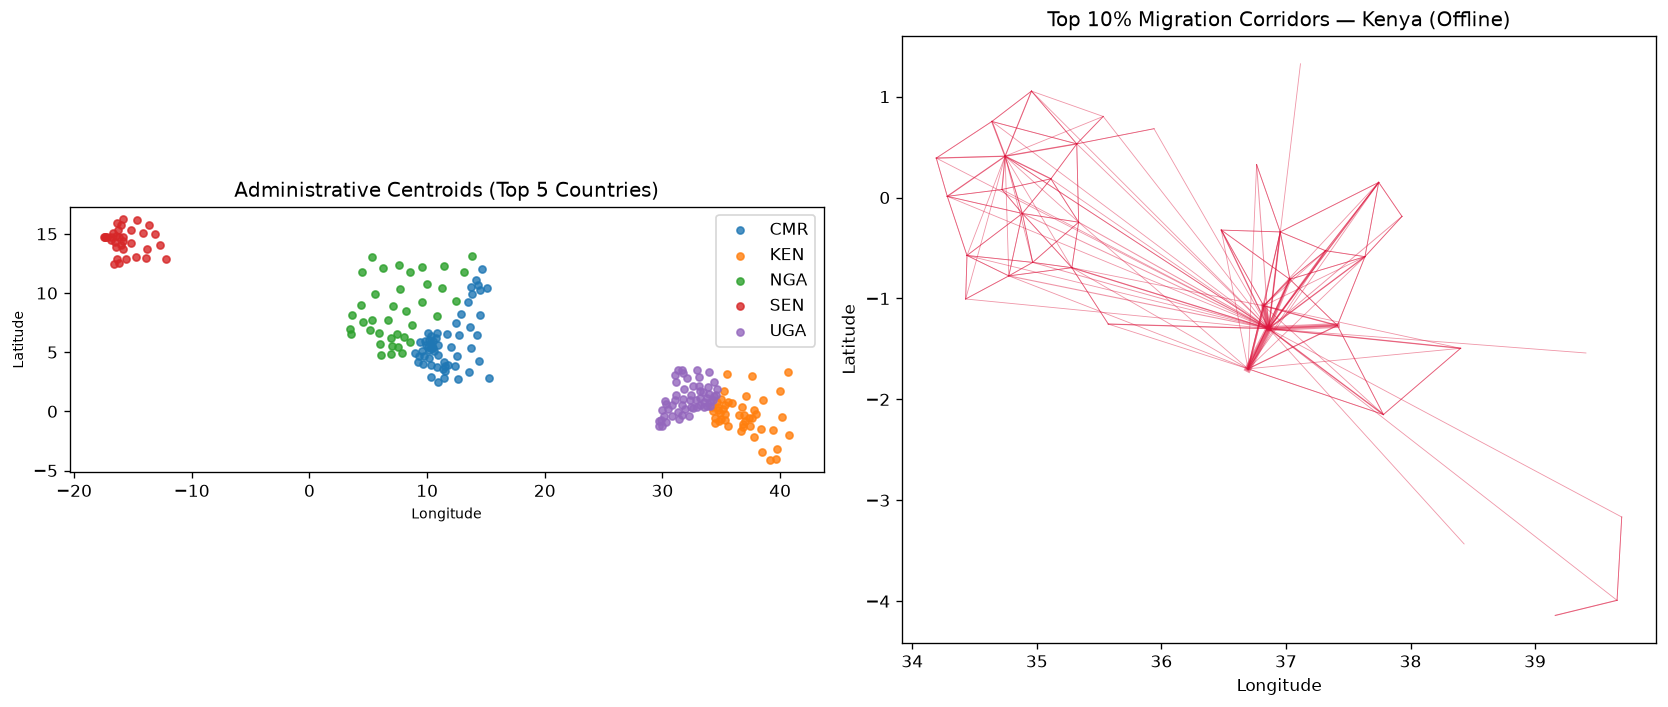

In [7]:
top5_centroids = centroids_gdf[centroids_gdf["ISO"].isin(TOP_5_COUNTRIES)].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Centroid distribution across top 5 countries
top5_centroids.plot(ax=axes[0], column="ISO", legend=True, markersize=18, alpha=0.8)
axes[0].set_title("Administrative Centroids (Top 5 Countries)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Right: Top 10% largest migration corridors in Kenya (offline line plot)
ken_df = flows_enriched[flows_enriched["ISO"] == "KEN"]
ken_top = ken_df[ken_df["PrdMIG"] >= ken_df["PrdMIG"].quantile(0.90)]

for _, row in ken_top.iterrows():
    lw = max(0.5, (row["PrdMIG"] / ken_top["PrdMIG"].max()) * 4.0)
    axes[1].plot([row["LONFR"], row["LONTO"]], [row["LATFR"], row["LATTO"]], lw=lw, alpha=0.45, color="crimson")

axes[1].set_title("Top 10% Migration Corridors — Kenya (Offline)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

### 8. Machine Learning Baseline
Train a baseline `RandomForestRegressor` to predict log-transformed migration volume (`log1p(PrdMIG)`) from spatial and structural features (`dist_km`, coordinates, and country encoding), evaluating performance with MAE and $R^2$.

In [8]:
ml_df = flows_enriched[["ISO", "LONFR", "LATFR", "LONTO", "LATTO", "dist_km", "PrdMIG"]].copy()
ml_df["log_flow"] = np.log1p(ml_df["PrdMIG"])

X = pd.get_dummies(ml_df.drop(columns=["PrdMIG", "log_flow"]), columns=["ISO"], drop_first=False)
y = ml_df["log_flow"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, max_depth=14, n_jobs=-1, random_state=42)
model.fit(X_train, y_train)

preds_log = model.predict(X_test)
mae_log = mean_absolute_error(y_test, preds_log)
r2_log = r2_score(y_test, preds_log)

print(f"Baseline Random Forest (target = log1p(PrdMIG)) -> MAE: {mae_log:.4f} | R2: {r2_log:.4f}")

Baseline Random Forest (target = log1p(PrdMIG)) -> MAE: 0.3386 | R2: 0.8603


### 9. Save All Outputs
Export cleaned datasets, top-5 country comparison tables, and summary figures to `outputs/` for reproducibility and portfolio sharing.

In [9]:
clean_flows_path = OUTPUT_DIR / "cleaned_migration_flows.csv"
summary_path = OUTPUT_DIR / "top5_countries_summary.csv"
fig_path = OUTPUT_DIR / "top5_countries_comparison.png"

flows_enriched.to_csv(clean_flows_path, index=False)
country_summary.to_csv(summary_path)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
country_summary["total_migrants"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Total 5-Year Migrants (Top 5 Countries)")
axes[0].set_ylabel("Migrants")
axes[0].tick_params(axis="x", rotation=0)

country_summary["mean_dist_km"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Mean Flow Distance (km)")
axes[1].set_ylabel("Kilometers")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(fig_path, dpi=150)
plt.close(fig)

print("Saved outputs:")
print("-", clean_flows_path)
print("-", summary_path)
print("-", fig_path)

Saved outputs:
- /Users/alaamahmoud/Desktop/Africa_1km_Internal_Migration_Flows 3/AfricaـFlows 3/outputs/cleaned_migration_flows.csv
- /Users/alaamahmoud/Desktop/Africa_1km_Internal_Migration_Flows 3/AfricaـFlows 3/outputs/top5_countries_summary.csv
- /Users/alaamahmoud/Desktop/Africa_1km_Internal_Migration_Flows 3/AfricaـFlows 3/outputs/top5_countries_comparison.png
